# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [1]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## 1. Data Collection


In [2]:
import pandas as pd
import os

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [3]:
def keep_top_n(df, column, n):
    top_values = df[column].value_counts().head(n).index.to_list()
    filtered_df = df[df[column].isin(top_values)]
    return filtered_df

In [4]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [5]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [6]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()
    
    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]
    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].to_dict(orient='records')
    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    filtered_genres_df = keep_top_n(genres_df, "genres", 5)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['lyrics'].str.strip() != '']
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [7]:
final_df_path = "data/final_data.csv"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_csv(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_csv(final_df_path, index=False)
    
data.head()

,id,genres,song,tags,audio_stats,lyrics
0,0009fFIM1eYThaPg,pop,Rain on Me,"pop,british,female vocalists,dance,cheryl cole","{'MFCC000': 23.622419357299805, 'MFCC001': -14...",sunni day get nowher hide cloud sky pretend ge...
1,00P2bHdWFkghmDqz,soul,Tell Me a Tale,"fip,soul","{'MFCC000': 23.64550018310547, 'MFCC001': -2.0...",tell tale alway sing song alway tell stori rea...
2,00XWljDxNBgBKEEA,pop,Y cómo es él?,"jose luis perales,spanish,pop","{'MFCC000': 21.851207733154297, 'MFCC001': -14...",look eye would swear someth new tell start wom...
3,00b6fV3nx5z2b8Ls,pop,ABC,"glee,pop,cover,glee cast","{'MFCC000': 23.93406867980957, 'MFCC001': -16....",buhbuh buh buhbuh buhbuh buh buhbuh go school ...
4,013QDoTqbexEwkHr,pop,Patience,"pop,george michael,6 of 10 stars","{'MFCC000': 20.773107528686523, 'MFCC001': 0.3...",like convers noon stop breath imagin god alrea...


## 2. Feature Extraction

## 3. Visualization and Analysis

In [8]:
wordcloud_df = data[['genres','tags']]
rap_df = wordcloud_df[wordcloud_df['genres'] == 'rap']
rock_df = wordcloud_df[wordcloud_df['genres'] == 'rock'] 


rap_tags = " ".join(rap_df['tags'].dropna())
rock_tags = " ".join(rock_df['tags'].dropna())

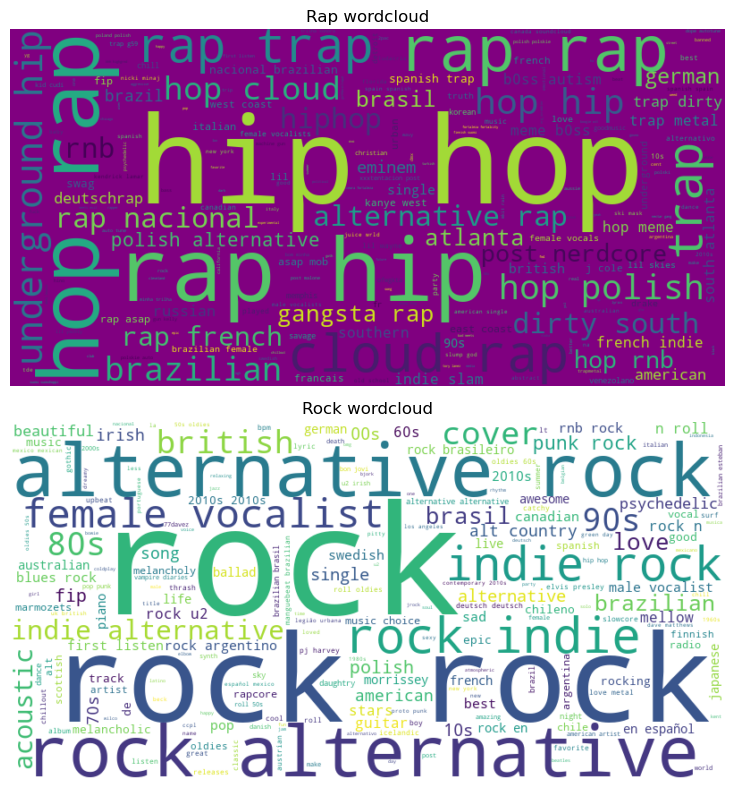

In [9]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

wordcloud_rap = WordCloud(width=800, height=400, background_color='purple').generate(rap_tags)
wordcloud_rock = WordCloud(width=800, height=400, background_color='white').generate(rock_tags)


fig, ax = plt.subplots(2, 1, figsize=(20,8))
ax[0].imshow(wordcloud_rap, interpolation="bilinear")
ax[0].set_title("Rap wordcloud")
ax[0].axis("off")

ax[1].imshow(wordcloud_rock, interpolation="bilinear")
ax[1].set_title("Rock wordcloud")
ax[1].axis("off")
plt.tight_layout()
plt.show()

In [16]:
import re
import numpy as np
from gensim.models import Word2Vec

#Προεπεξεργασία Lyrics

def preprocess_lyrics(text):
    if not isinstance(text, str):
        return []
    #Αφαίρεση περιεχομένου σε αγκύλες π.χ. [Chorus]
    text = re.sub(r'\[.*?\]', '', text)
    #Μετατροπή σε πεζά (για να αναγνωρίζουμε ίδιες λέξεις)
    text = text.lower()
    #Κρατάμε μόνο γράμματα και αποστροφές, όλα τα άλλα τα πετάμε πχ. αριθμούς
    text = re.sub(r"[^a-z\s']", '', text)
    #Βγάζουμε τα tokens τώρα αλλά όχι τις λέξεις με 2 ή λιγότερα γράμματα (είναι άχρηστες)
    tokens = [t for t in text.split() if len(t) >= 2]
    return tokens

#Εφαρμογή
print("Προεπεξεργασία lyrics...")
data['lyrics_tokens'] = data['lyrics'].apply(preprocess_lyrics)

#Παράδειγμα για να ελέγξουμε ότι το κάναμε σωστά
print(f"Παράδειγμα tokens:\n{data['lyrics_tokens'].iloc[32][:15]}")
print(f"Σύνολο τραγουδιών: {len(data)}")

Προεπεξεργασία lyrics...
Παράδειγμα tokens:
['think', 'space', 'soul', 'fall', 'find', 'earth', 'leavin', 'know', 'face', 'think', 'fall', 'place', 'get', 'anywher', 'anywher']
Σύνολο τραγουδιών: 11571


In [20]:

#Εκπαίδευση Word2Vec

#Το corpus θα είναι η λίστα με τα tokenized lyrics που προέκυψε παραπάνω,
#την οποία μετατρέπουμε σε απλή python λίστα για να αναγνωρίζεται από το μον΄τελο.
corpus = data['lyrics_tokens'].tolist()

print("Εκπαίδευση Word2Vec μοντέλου...")
w2v_model = Word2Vec(
    sentences=corpus,
    vector_size=100,   #Διάσταση embedding
    window=5,          #Πλαίσιο γειτονικών λέξεων (κοιτάζει τις 2 αριστερές και 2 δεξιές λέξεις)
    min_count=3,       #Αγνόησε λέξεις που εμφανίζονται < 3 φορές (δεν βοηθάνε να βγάλουμε συμπεράσματα)
    workers=4,         #Παράλληλη εκπαίδευση (4 CPUs)
    epochs=10,         #Θα διαβάσει το corpus 10 φορές
    sg=1               #Θα προσπαθεί μέσω μιας λέξης να προβλέπει τις γύρω λέξεις (skip gram algorithm)
)

print(f"Συνολική ποσότητα λέξεων: {len(w2v_model.wv)}")
print(f"Παράδειγμα - λέξεις κοντά στο 'say': {w2v_model.wv.most_similar('say', topn=5)}")

#Αποθήκευση 
w2v_model.save("data/word2vec_lyrics.model")
print("Μοντέλο αποθηκεύτηκε!")

Εκπαίδευση Word2Vec μοντέλου...
Συνολική ποσότητα λέξεων: 13429
Παράδειγμα - λέξεις κοντά στο 'say': [('whawhawhawhawhat', 0.739639937877655), ('cheater', 0.6918770670890808), ('tell', 0.6916870474815369), ('denyin', 0.682937741279602), ('knever', 0.6769526600837708)]
Μοντέλο αποθηκεύτηκε!


In [18]:

#Δημιουργία Song Embeddings 

#Η παρακάτω συνάρτηση επεξεργάζεται 1 τραγο΄ύδι κάθε φορά, παίρνει κάθε λέξη που έχουμε βάλει από πριν στα tokens του τραγουδιού αυτού
#και τοποθετεί το διάνυσμά της (100 αριθμοί) στον πίνακα vectors. 'Υστερα υπολογίζει το μέσο όρο ανά στήλη των διανυσμάτων του πίνακα και
#δημιουργεί το song embedding.

def get_song_embedding(tokens, model, vector_size=100):
  
    vectors = []
    
    for token in tokens: #Για κάθε λέξη που ανήκει στο word2vec model μας, βάλε το διάνυσμά της στον πίνακα vectors
        if token in model.wv:
            vectors.append(model.wv[token])
    
    if len(vectors) == 0:
        #Έλεγχος σφάλματος
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0) #Επέστρεψε το μέσο όρο αν΄ά στήλη όλων των λέξεων-διανυσμάτων του τραγουδιού που είναι το song embedding.

print("Δημιουργία song embeddings...")
data['text_embedding'] = data['lyrics_tokens'].apply(
    lambda tokens: get_song_embedding(tokens, w2v_model, vector_size=100) #Lambda για να περάσουμε και τα 3 ορίσματα μαζί
)

#Αποθηκεύουμε τα embeddings σε ξεχωριστό αρχείο, με μορφή 2D πίνακα
text_embeddings_matrix = np.vstack(data['text_embedding'].values)
np.save("data/text_embeddings.npy", text_embeddings_matrix)

print(f"Shape των text embeddings: {text_embeddings_matrix.shape}")
#Αναμενόμενο: (αριθμός τραγουδιών, 100)
print("Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy")

Δημιουργία song embeddings...
Shape των text embeddings: (11571, 100)
Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy
